# Backtest of the basis trading rule

**Added in November 2026.** The original notebook, from October 2025, fits the model and sets out a trading rule, but the copy in this repository never tests the rule. This notebook does, on the same data:

1. Is the basis stationary?
2. How does the rule perform in sample, out of sample, and walk-forward?

No trading costs are included, so every figure here flatters the rule.

In [1]:
import warnings

import numpy as np
import pandas as pd
import statsmodels.api as sm
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import adfuller, coint

warnings.simplefilter("ignore", FutureWarning)

data = pd.read_csv("data/Apples Data Set.csv", header=0, index_col=0)
data.index = pd.to_datetime(data.index, dayfirst=True)

uk = (data["UK Apples (GBP)"] / data["EURGBP"]).to_numpy()     # UK price in euros
ger = data["German Apples (EUR)"].to_numpy()
dates = data.index
n = len(data)
print(f"{n} daily observations, {dates[0].date()} to {dates[-1].date()}")

2250 daily observations, 2015-01-01 to 2023-08-16


## The model, as in the original notebook

The hedge ratio comes from an OLS regression of the UK price on the German price. The residual is the basis, and an AR(1) regression on it gives the Ornstein–Uhlenbeck parameters.

In [2]:
def fit(u, g):
    """Hedge ratio by OLS, then OU parameters of the basis from an AR(1) regression.

    Returns the intercept, the hedge ratio, the long-run mean of the basis,
    its stationary standard deviation and its half-life in trading days.
    """
    const, alpha = sm.OLS(u, sm.add_constant(g)).fit().params
    b = u - (const + alpha * g)
    c, a = sm.OLS(b[1:], sm.add_constant(b[:-1])).fit().params
    if not 0 < a < 1:                       # no mean reversion in this window
        return const, alpha, b.mean(), b.std(ddof=1), np.inf
    resid_var = np.var(b[1:] - (c + a * b[:-1]), ddof=1)
    mu = c / (1 - a)
    sd = np.sqrt(resid_var / (1 - a**2))
    half_life = np.log(2) / -np.log(a)
    return const, alpha, mu, sd, half_life


const, alpha, mu, sd, half_life = fit(uk, ger)
basis = uk - (const + alpha * ger)
ar1 = np.exp(-np.log(2) / half_life)
print(f"hedge ratio {alpha:.3f}, intercept {const:.2f}")
print(f"basis: long-run mean {mu:.2f}, stationary sd {sd:.2f}, "
      f"AR(1) coefficient {ar1:.4f}, half-life {half_life:.1f} trading days")

hedge ratio 1.689, intercept -41.14
basis: long-run mean 2.57, stationary sd 33.32, AR(1) coefficient 0.9869, half-life 52.8 trading days


## 1. Is the basis stationary?

The rule only makes sense if the basis keeps returning to its mean. Two standard checks: an augmented Dickey–Fuller test on the basis, and the Engle–Granger test for cointegration between the two prices. In both, the null hypothesis is that there is **no** mean reversion, so a small p-value is what the strategy needs.

ADF on the basis:        statistic  -0.13, p-value 0.95
Engle-Granger (UK, DE):  statistic  -0.14, p-value 0.98

first half  (2015-01-01 to 2019-04-24): ADF p-value 0.41, sd of basis   8.5, sd of daily change 3.0
second half (2019-04-25 to 2023-08-16): ADF p-value 0.97, sd of basis  43.1, sd of daily change 7.0


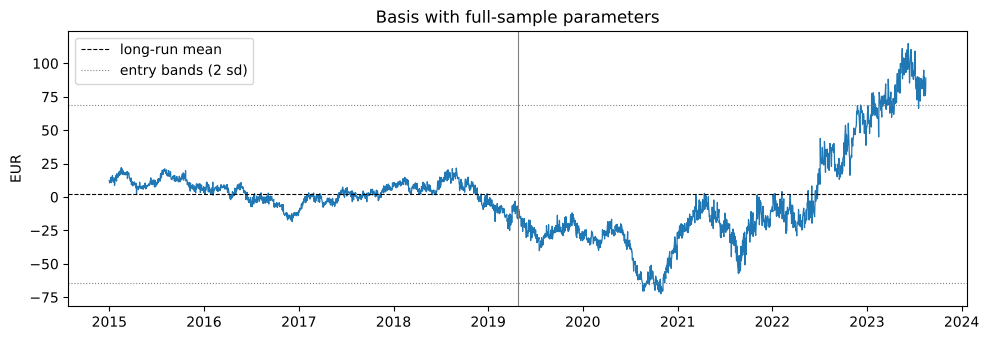

In [3]:
adf_stat, adf_p = adfuller(basis, autolag="AIC")[:2]
eg_stat, eg_p = coint(uk, ger, trend="c", autolag="AIC")[:2]
print(f"ADF on the basis:        statistic {adf_stat:6.2f}, p-value {adf_p:.2f}")
print(f"Engle-Granger (UK, DE):  statistic {eg_stat:6.2f}, p-value {eg_p:.2f}")

half = n // 2
print()
for label, part in [("first half ", slice(0, half)), ("second half", slice(half, n))]:
    p = adfuller(basis[part], autolag="AIC")[1]
    print(f"{label} ({dates[part][0].date()} to {dates[part][-1].date()}): "
          f"ADF p-value {p:.2f}, sd of basis {basis[part].std(ddof=1):5.1f}, "
          f"sd of daily change {np.diff(basis[part]).std(ddof=1):.1f}")

fig, ax = plt.subplots(figsize=(10, 3.5))
ax.plot(dates, basis, lw=0.9)
ax.axhline(mu, color="black", lw=0.8, ls="--", label="long-run mean")
for k in (2, -2):
    ax.axhline(mu + k * sd, color="gray", lw=0.8, ls=":", label="entry bands (2 sd)" if k == 2 else None)
ax.axvline(dates[half], color="gray", lw=0.8)
ax.set_title("Basis with full-sample parameters")
ax.set_ylabel("EUR")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

Neither test comes close to rejecting. The 53-day half-life rests on an AR(1) coefficient of 0.987, and these tests cannot tell that apart from 1, which would mean no mean reversion at all. The basis is quiet in the first half of the sample and then drifts, with daily moves more than twice as large.

So the premise is already in doubt before any trade is simulated. The backtest below asks what that costs.

## 2. The rule

From the original notebook, with the z-score measured against the stationary standard deviation of the fitted OU process:

- enter when the basis is more than 2 standard deviations from its mean, short the spread above and long below
- exit when it is back within 0.5
- stop out beyond 3

Two details the original left open, fixed here before running anything:

- after a stop-out, no new trade until the basis has come back inside the exit band
- the signal uses the close of day *t*. The trade is done either at that same close, or one day later (`delay=1`)

One unit of the spread is long one UK apple and short `alpha` German apples. Returns are per euro of gross exposure, the two legs added together.

In [4]:
ENTER, EXIT, STOP = 2.0, 0.5, 3.0


def backtest(const, alpha, mu, sd, start, delay=0):
    """Trade the rule from day `start`.

    The four parameter arrays hold, for each day t, values estimated only from
    data before t. `delay` is the number of days between the signal and the
    trade. Returns the daily return series, the trades as (signal day in,
    signal day out, direction, how it ended) and a summary.
    """
    z = (uk - (const + alpha * ger) - mu) / sd

    signal = np.zeros(n)
    trades = []
    state, armed, entry = 0, True, None
    for t in range(start, n):
        if state != 0:
            if abs(z[t]) > STOP:
                trades.append((entry, t, state, "stop"))
                state, armed = 0, False
            elif abs(z[t]) < EXIT:
                trades.append((entry, t, state, "exit"))
                state = 0
        if state == 0:
            if not armed and abs(z[t]) < EXIT:
                armed = True
            if armed and ENTER < abs(z[t]) <= STOP:
                state, entry = -int(np.sign(z[t])), t
        signal[t] = state
    if state != 0:
        trades.append((entry, n - 1, state, "open"))

    # The position actually held at each close, then vectorised P&L:
    # yesterday's position times today's move in the hedged spread.
    pos = signal if delay == 0 else np.concatenate([np.zeros(delay), signal[:-delay]])
    move = np.diff(uk) - alpha[:-1] * np.diff(ger)
    gross = uk[:-1] + np.abs(alpha[:-1]) * ger[:-1]
    ret = np.zeros(n)
    held = pos[:-1] != 0
    ret[1:][held] = pos[:-1][held] * move[held] / gross[held]

    r = ret[start:]
    cum = np.cumsum(r)
    drawdown = (np.maximum.accumulate(np.maximum(cum, 0)) - cum).max()
    per_trade = [ret[e + 1 + delay : x + 1 + delay].sum() for e, x, _, _ in trades]
    summary = {
        "Total return %": 100 * cum[-1],
        "Sharpe": r.mean() / r.std(ddof=1) * np.sqrt(252) if r.std() > 0 else np.nan,
        "Max drawdown %": 100 * drawdown,
        "Trades": len(trades),
        "Hit rate %": 100 * np.mean([x > 0 for x in per_trade]) if trades else np.nan,
        "Stop-outs": sum(1 for t in trades if t[3] == "stop"),
    }
    return ret, trades, summary


def constant(params):
    return tuple(np.full(n, p) for p in params[:4])


def walk_forward(window, refit):
    """Re-estimate every `refit` days on the previous `window` days only."""
    arrays = tuple(np.full(n, np.nan) for _ in range(4))
    for t in range(window, n):
        if (t - window) % refit == 0:
            current = fit(uk[t - window : t], ger[t - window : t])[:4]
        for arr, value in zip(arrays, current):
            arr[t] = value
    return arrays

## 3. Results

Three ways of choosing the parameters, from least to most honest:

- **In sample.** One fit on the whole history, as in the original notebook, then traded over that same history. The rule sees the future.
- **Frozen.** Fit on the first half, then trade the second half with those parameters fixed.
- **Walk-forward.** Re-estimate on a rolling window of past data and trade forward. The original notebook says to re-estimate periodically without saying how, so I ran four window lengths and two refit frequencies and report all of them.

Every out-of-sample test trades the same period, the second half of the data.

In [5]:
setups = {"In sample: full-history fit, whole period": (constant(fit(uk, ger)), 0),
          "Frozen: first-half fit": (constant(fit(uk[:half], ger[:half])), half)}
for refit, label in ((63, "quarterly"), (21, "monthly")):
    for window in (252, 504, 756, 1008):
        setups[f"Walk-forward: {window // 252}-year window, {label} refit"] = (walk_forward(window, refit), half)

runs = {delay: {name: backtest(*params, start=start, delay=delay) for name, (params, start) in setups.items()}
        for delay in (0, 1)}


def table(delay):
    out = pd.DataFrame({name: summary for name, (_, _, summary) in runs[delay].items()}).T
    out[["Trades", "Stop-outs"]] = out[["Trades", "Stop-outs"]].astype(int)
    return out.round(2)


print(f"Out-of-sample period: {dates[half].date()} to {dates[-1].date()}")
print("Trading at the same close that produced the signal:")
table(0)

Out-of-sample period: 2019-04-25 to 2023-08-16
Trading at the same close that produced the signal:


,Total return %,Sharpe,Max drawdown %,Trades,Hit rate %,Stop-outs
"In sample: full-history fit, whole period",3.45,0.09,8.24,2,50.00,1
Frozen: first-half fit,11.00,0.43,6.04,18,55.56,8
"Walk-forward: 1-year window, quarterly refit",38.58,1.01,6.31,17,82.35,3
"Walk-forward: 2-year window, quarterly refit",8.20,0.20,6.20,7,42.86,4
"Walk-forward: 3-year window, quarterly refit",-2.90,-0.09,9.14,7,42.86,4
"Walk-forward: 4-year window, quarterly refit",-10.57,-0.32,15.78,6,16.67,5
"Walk-forward: 1-year window, monthly refit",32.60,0.86,7.20,15,80.00,3
"Walk-forward: 2-year window, monthly refit",15.27,0.37,7.38,9,55.56,4
"Walk-forward: 3-year window, monthly refit",0.66,0.02,9.10,8,50.00,4
"Walk-forward: 4-year window, monthly refit",-9.22,-0.29,11.16,7,28.57,5


The answer depends almost entirely on how much history the parameters are estimated from. With a one-year window the rule looks good. With three or four years it loses money. That spread of outcomes is not what a real edge looks like, so the next question is where the one-year result comes from.

In [6]:
change = np.diff(basis)
autocorr = np.corrcoef(change[:-1], change[1:])[0, 1]
print(f"Lag-1 autocorrelation of the daily change in the basis: {autocorr:.2f}")

name = "Walk-forward: 1-year window, quarterly refit"
ret, trades, _ = runs[0][name]
first_day = sum(ret[e + 1] for e, _, _, _ in trades)
print(f"{name}: {100 * first_day / ret.sum():.0f}% of the total return is earned "
      f"on the first day after entry")

Lag-1 autocorrelation of the daily change in the basis: -0.48
Walk-forward: 1-year window, quarterly refit: 43% of the total return is earned on the first day after entry


An autocorrelation near −0.5 is what day-to-day noise looks like: a jump one day, undone the next. Most of the daily movement in the basis is that noise, sitting on top of the slow drift.

So the rule is often triggered by a one-day spike, and the backtest lets it trade at the very price that made the spike. The fair test is to act on the signal one day later.

In [7]:
print("Trading one day after the signal:")
table(1)

Trading one day after the signal:


,Total return %,Sharpe,Max drawdown %,Trades,Hit rate %,Stop-outs
"In sample: full-history fit, whole period",5.38,0.13,8.24,2,50.00,1
Frozen: first-half fit,-2.57,-0.11,6.51,18,55.56,8
"Walk-forward: 1-year window, quarterly refit",9.24,0.25,10.06,17,64.71,3
"Walk-forward: 2-year window, quarterly refit",2.32,0.06,7.42,7,42.86,4
"Walk-forward: 3-year window, quarterly refit",-9.92,-0.30,13.30,7,14.29,4
"Walk-forward: 4-year window, quarterly refit",-15.74,-0.48,20.39,6,16.67,5
"Walk-forward: 1-year window, monthly refit",14.70,0.37,6.91,15,73.33,3
"Walk-forward: 2-year window, monthly refit",2.04,0.05,9.16,9,55.56,4
"Walk-forward: 3-year window, monthly refit",-11.21,-0.35,13.71,8,25.00,4
"Walk-forward: 4-year window, monthly refit",-12.47,-0.39,15.06,7,14.29,5


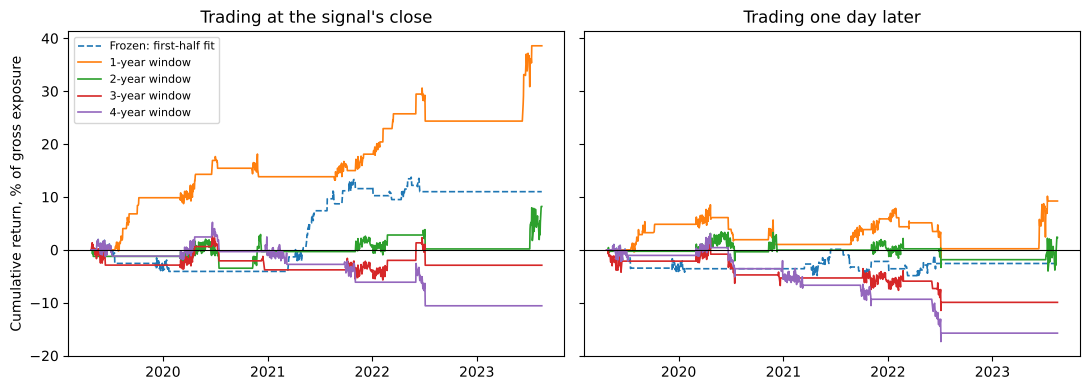

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
shown = ["Frozen: first-half fit"] + [f"Walk-forward: {w}-year window, quarterly refit" for w in (1, 2, 3, 4)]
styles = ["--", "-", "-", "-", "-"]
for ax, delay, title in ((axes[0], 0, "Trading at the signal's close"),
                         (axes[1], 1, "Trading one day later")):
    for name, ls in zip(shown, styles):
        ret = runs[delay][name][0]
        ax.plot(dates[half:], 100 * np.cumsum(ret[half:]), ls=ls, lw=1.2,
                label=name.replace("Walk-forward: ", "").replace(", quarterly refit", ""))
    ax.axhline(0, color="black", lw=0.8)
    ax.set_title(title)
    ax.set_xticks(pd.to_datetime([f"{y}-01-01" for y in range(2020, 2024)]))
    ax.set_xticklabels(range(2020, 2024))
axes[0].set_ylabel("Cumulative return, % of gross exposure")
axes[0].legend(loc="upper left", fontsize=8)
plt.tight_layout()
plt.show()

## What this shows

**The basis is not stationary on this data.** Neither test rejects (p-values of 0.95 and 0.98), so the 53-day half-life in the original notebook is not an estimate to rely on.

**With the original full-history parameters the rule barely trades.** It makes 2 trades in eight and a half years.

**Out of sample, the result is set by a choice the original notebook never made.** Estimating on one year of history gives a Sharpe ratio of about 1. Estimating on four years gives about −0.3. I tried eight walk-forward settings after seeing the data, so the best of them is not evidence of an edge.

**The good results come from an execution assumption.** Daily changes in the basis are mostly one-day noise (autocorrelation of −0.48). The rule enters on a spike, and the backtest fills it at the spike. Acting one day later, the best out-of-sample Sharpe ratio is 0.37 and the frozen fit turns negative. With a little over four years of data, a Sharpe ratio has to be near 1 before it stands clear of zero, and none of these is.

**I would not trade the rule as written.** If the one-day reversal is real and can be dealt at the printed price, that is a different strategy from the one specified: a short-horizon reversal trade, which needs its own design and, above all, its own costs. None are modelled here.
